# Q9: relative excitation-inhibition balance by brain area

This notebook visualizes the outputs of `q9_fooof.py` and `q9_fooof_stats.R`. Following [Pochinok et al. (2024)](https://doi.org/10.1038/s41467-024-44983-z), the primary proxy is the fixed, peak-free FOOOF exponent over 25–45 Hz, with fits retained at $R^2 \geq 0.95$. The requested adaptation is applied before fitting: Welch PSD is calculated separately for every channel and the linear PSDs are then combined by a pointwise median, yielding one PSD per mouse and area. A smaller exponent (flatter spectrum) indicates stronger relative excitation.


In [1]:
from pathlib import Path
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

repo = Path.cwd().resolve()
if repo.name == 'questions':
    repo = repo.parents[1]
elif repo.name == 'code':
    repo = repo.parent
output = repo / 'results' / 'q9'
psd = pd.read_csv(output / 'q9_mouse_area_psd.csv')
fits = pd.read_csv(output / 'q9_fooof_fits.csv')
curves = pd.read_csv(output / 'q9_fooof_curves.csv')
inclusion = pd.read_csv(output / 'q9_stats_fit_inclusion.csv')
means = pd.read_csv(output / 'q9_stats_means.csv')
contrasts = pd.read_csv(output / 'q9_stats_contrasts.csv')
config = json.loads((output / 'q9_config.json').read_text())
colors = {1: '#0072B2', 2: '#D55E00', 3: '#00856A'}
sns.set_theme(style='ticks', context='notebook')

def save_figure(fig, name):
    fig.savefig(output / f'q9_{name}.png', dpi=240, bbox_inches='tight')
    fig.savefig(output / f'q9_{name}.pdf', bbox_inches='tight')

print(f"{psd[['mouse_id', 'brain_area']].drop_duplicates().shape[0]} mouse-area PSDs")
print(f"FOOOF {config['fooof']['version']} | primary range {config['fooof']['primary_range_hz']} Hz")


54 mouse-area PSDs
FOOOF 1.1.1 | primary range [25.0, 45.0] Hz


## Mouse-area spectra and offset-normalized aperiodic component

Thin lines are individual mouse-area spectra and thick lines are area medians. The second panel removes each fit's offset to expose the 25–45 Hz slope, analogous to Fig. 1E in the paper.


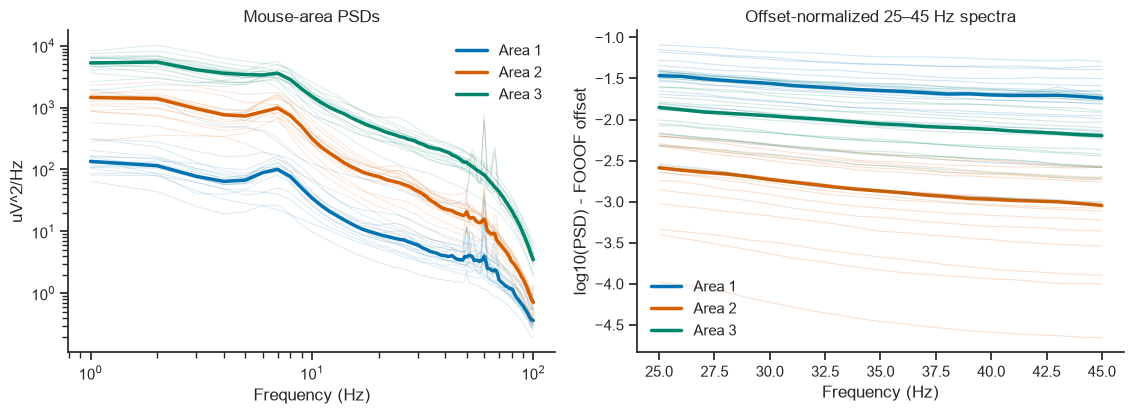

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.3))
for area, area_rows in psd.groupby('brain_area'):
    wide = area_rows.pivot(index='frequency_hz', columns='mouse_id', values='psd')
    axes[0].plot(wide.index, wide, color=colors[area], alpha=.15, lw=.7)
    axes[0].plot(wide.index, wide.median(axis=1), color=colors[area], lw=2.5, label=f'Area {area}')
primary_curves = curves[curves.fit_range.eq('25-45')]
for area, area_rows in primary_curves.groupby('brain_area'):
    wide = area_rows.pivot(index='frequency_hz', columns='mouse_id', values='observed_log10_psd_offset_normalized')
    axes[1].plot(wide.index, wide, color=colors[area], alpha=.18, lw=.8)
    axes[1].plot(wide.index, wide.median(axis=1), color=colors[area], lw=2.5, label=f'Area {area}')
axes[0].set(xscale='log', yscale='log', xlabel='Frequency (Hz)', ylabel=psd.psd_unit.iloc[0], title='Mouse-area PSDs')
axes[1].set(xlabel='Frequency (Hz)', ylabel='log10(PSD) - FOOOF offset', title='Offset-normalized 25–45 Hz spectra')
for ax in axes:
    ax.legend(frameon=False)
sns.despine()
fig.tight_layout()
save_figure(fig, 'psd_and_normalized_aperiodic')


## FOOOF quality control


,sum,count
brain_area,,
1,15,18
2,17,18
3,18,18


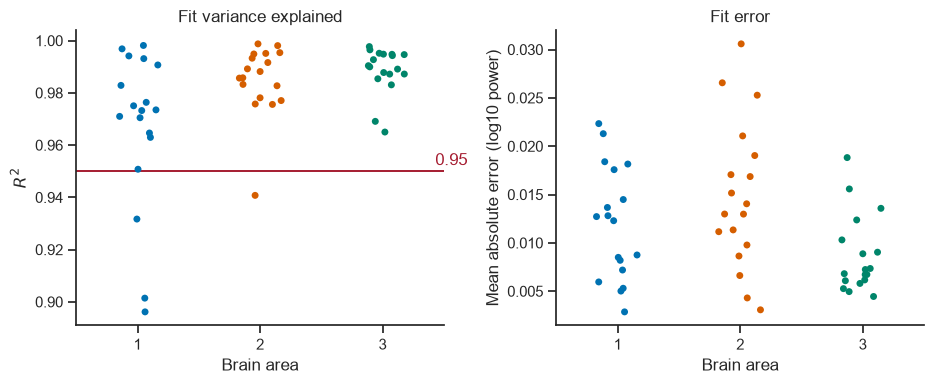

In [3]:
primary = fits[fits.fit_range.eq('25-45')].copy()
fig, axes = plt.subplots(1, 2, figsize=(9.5, 4))
sns.stripplot(data=primary, x='brain_area', y='r_squared', hue='brain_area', palette=colors, legend=False, jitter=.18, ax=axes[0])
axes[0].axhline(.95, color='#A51C30', lw=1.4)
axes[0].text(2.43, .951, '0.95', color='#A51C30', va='bottom')
sns.stripplot(data=primary, x='brain_area', y='mean_absolute_error_log10', hue='brain_area', palette=colors, legend=False, jitter=.18, ax=axes[1])
axes[0].set(xlabel='Brain area', ylabel='$R^2$', title='Fit variance explained')
axes[1].set(xlabel='Brain area', ylabel='Mean absolute error (log10 power)', title='Fit error')
sns.despine()
fig.tight_layout()
save_figure(fig, 'fooof_quality')
primary.groupby('brain_area').passes_r_squared.agg(['sum', 'count'])


## Representative peak-free FOOOF fits

For each area, the displayed mouse has the median primary-fit $R^2$ among retained fits.


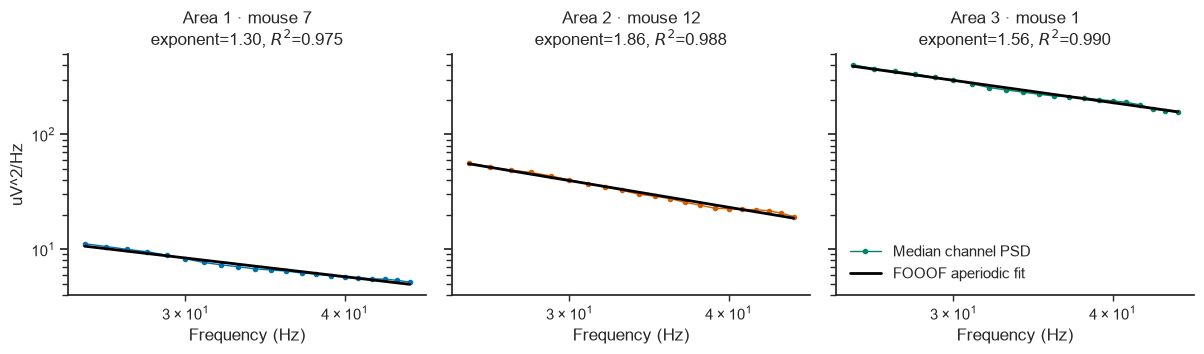

In [4]:
valid = primary[primary.passes_r_squared].copy()
examples = valid.loc[valid.groupby('brain_area').r_squared.apply(lambda x: (x - x.median()).abs().idxmin())]
fig, axes = plt.subplots(1, 3, figsize=(12.2, 3.7), sharey=True)
for ax, row in zip(axes, examples.itertuples()):
    data = curves[(curves.mouse_id == row.mouse_id) & (curves.brain_area == row.brain_area) & curves.fit_range.eq('25-45')]
    ax.loglog(data.frequency_hz, data.observed_psd, 'o-', ms=3, lw=1, color=colors[row.brain_area], label='Median channel PSD')
    ax.loglog(data.frequency_hz, data.aperiodic_fit_psd, color='black', lw=2, label='FOOOF aperiodic fit')
    ax.set_title(f'Area {row.brain_area} · mouse {row.mouse_id}\nexponent={row.aperiodic_exponent:.2f}, $R^2$={row.r_squared:.3f}')
    ax.set_xlabel('Frequency (Hz)')
axes[0].set_ylabel(psd.psd_unit.iloc[0])
axes[-1].legend(frameon=False, loc='lower left')
sns.despine()
fig.tight_layout()
save_figure(fig, 'fooof_examples')


## Primary area comparison

Gray lines connect the three observed exponents from each mouse retained in the primary analysis. Colored points and intervals are mixed-model estimated marginal means and pointwise 95% confidence intervals. Lower values indicate stronger relative excitation.


,fit_range,area_a,area_b,exponent_difference_a_minus_b,exponent_lower_95,exponent_upper_95,relative_excitation_difference_a_minus_b,excitation_lower_95,excitation_upper_95,se,df,t_ratio,p_adjusted
6,25-45,1,2,-0.790727,-0.930507,-0.650946,0.790727,0.650946,0.930507,0.056492,28,-13.997199,9.425793e-14
7,25-45,1,3,-0.168703,-0.244721,-0.092684,0.168703,0.092684,0.244721,0.030723,28,-5.491161,2.114373e-05
8,25-45,2,3,0.622024,0.504722,0.739326,-0.622024,-0.739326,-0.504722,0.047407,28,13.120872,5.156986e-13


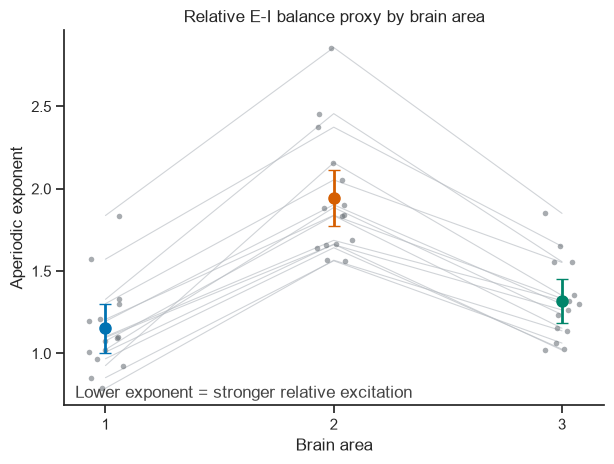

In [5]:
raw = inclusion[inclusion.fit_range.eq('25-45') & inclusion.complete_mouse_for_range].copy()
model_means = means[means.fit_range.eq('25-45')].copy()
fig, ax = plt.subplots(figsize=(6.3, 4.8))
for _, row in raw.pivot(index='mouse_id', columns='brain_area', values='aperiodic_exponent').iterrows():
    ax.plot([1, 2, 3], row[[1, 2, 3]], color='#B8BDC3', lw=.8, alpha=.65, zorder=1)
sns.stripplot(data=raw, x='brain_area', y='aperiodic_exponent', color='#626970', alpha=.55, jitter=.08, size=4, native_scale=True, ax=ax, zorder=2)
for row in model_means.itertuples():
    area = int(row.brain_area)
    ax.errorbar(area, row.exponent, yerr=[[row.exponent-row.exponent_lower_95], [row.exponent_upper_95-row.exponent]], fmt='o', ms=8, capsize=4, lw=2, color=colors[area], zorder=4)
ax.set(xticks=[1, 2, 3], xlabel='Brain area', ylabel='Aperiodic exponent', title='Relative E-I balance proxy by brain area')
ax.text(.02, .02, 'Lower exponent = stronger relative excitation', transform=ax.transAxes, color='#444444')
sns.despine()
fig.tight_layout()
save_figure(fig, 'primary_area_exponents')
contrasts[contrasts.fit_range.eq('25-45')]


## Supplementary Fig. 2 frequency-range sensitivity


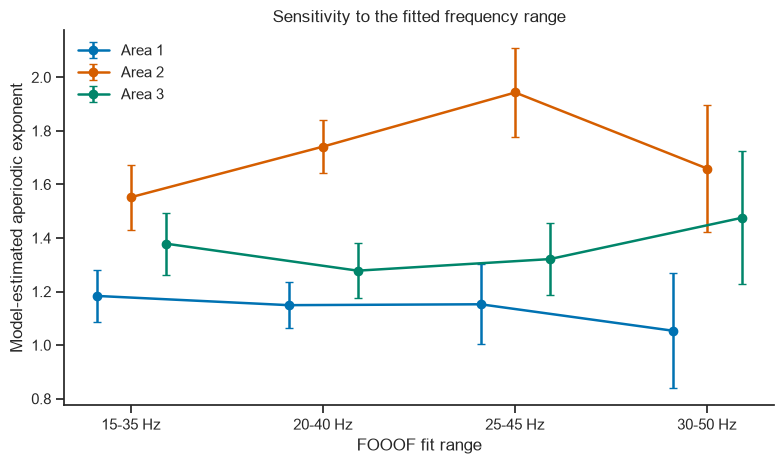

In [6]:
range_order = ['15-35', '20-40', '25-45', '30-50']
x = np.arange(len(range_order))
offsets = {1: -.18, 2: 0, 3: .18}
fig, ax = plt.subplots(figsize=(8, 4.8))
for area in [1, 2, 3]:
    rows = means[means.brain_area.eq(area)].set_index('fit_range').loc[range_order]
    ax.errorbar(x + offsets[area], rows.exponent, yerr=[rows.exponent-rows.exponent_lower_95, rows.exponent_upper_95-rows.exponent], fmt='o-', capsize=3, lw=1.8, color=colors[area], label=f'Area {area}')
ax.set(xticks=x, xticklabels=[f'{item} Hz' for item in range_order], xlabel='FOOOF fit range', ylabel='Model-estimated aperiodic exponent', title='Sensitivity to the fitted frequency range')
ax.legend(frameon=False)
sns.despine()
fig.tight_layout()
save_figure(fig, 'fit_range_sensitivity')


In [7]:
print((output / 'answer.txt').read_text())


Q9 answer: Brain area 1

The primary analysis used the 25-45 Hz FOOOF aperiodic exponent. A smaller exponent indicates a flatter spectrum and stronger relative excitation.
The mixed-effects model included 15 complete mice and gave F(2, 28) = 101.16, p < 0.0001.
Model-estimated exponents: area 1: 1.152 (95% CI 1.003 to 1.301); area 2: 1.943 (95% CI 1.775 to 2.111); area 3: 1.321 (95% CI 1.187 to 1.455) .
Area 1 had a significantly smaller exponent than both other areas and therefore the strongest relative excitation.

Sensitivity fits (Supplementary Fig. 2 ranges):
- 15-35 Hz: lowest exponent in area 1; answer = Brain area 1
- 20-40 Hz: lowest exponent in area 1; answer = Brain area 1
- 25-45 Hz: lowest exponent in area 1; answer = Brain area 1
- 30-50 Hz: lowest exponent in area 1; answer = Brain area 1

The aperiodic exponent is a population-level proxy for relative E-I balance, not a direct measurement of synaptic excitation or inhibition.

